In [1]:
!python -c "import seaborn; print(seaborn.__version__)"

0.13.2


In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [62]:
# -------------------------------------------------------------
# 0. Load Datasets
# -------------------------------------------------------------
# Using raw strings (r"...") prevents Windows path escape character issues
customers = pd.read_csv(r"D:\PDA Data\customers - customers.csv")
products = pd.read_csv(r"D:\PDA Data\products - products.csv")
sales = pd.read_csv(r"D:\PDA Data\sales - sales.csv")

# Set aesthetic visual style
sns.set_theme(style="whitegrid")


  Customer_ID   Customer_Name   Age  Gender      City Region
0        C101      Amit Patil  23.0    Male      Pune   West
1        C102      Priya Shah  35.0  Female    Mumbai   West
2        C103    Rahul Jadhav   NaN    Male    Nashik  North
3        C104  Sneha Kulkarni  42.0  Female  Kolhapur  South
4        C105      Neha Joshi  29.0    Male      pune   West


In [63]:
customers.head()


,Customer_ID,Customer_Name,Age,Gender,City,Region
0,C101,Amit Patil,23.0,Male,Pune,West
1,C102,Priya Shah,35.0,Female,Mumbai,West
2,C103,Rahul Jadhav,NaN,Male,Nashik,North
3,C104,Sneha Kulkarni,42.0,Female,Kolhapur,South
4,C105,Neha Joshi,29.0,Male,pune,West


In [67]:
customers.isna().sum()

Customer_ID      0
Customer_Name    0
Age              2
Gender           0
City             0
Region           0
dtype: int64

In [70]:
customers = customers.dropna()

In [71]:
sales.head()

,Transaction_ID,Customer_ID,Product_ID,Quantity,Amount,Payment_Mode,Order_Date
0,T1001,C117,P07,3,21000.0,Cash,2026-03-16
1,T1002,C106,P12,3,13500.0,UPI,2026-08-23
2,T1003,C101,P04,4,12000.0,NetBanking,2026-03-06
3,T1004,C128,P09,3,5400.0,NetBanking,2026-02-05
4,T1005,C118,P01,2,110000.0,Card,2026-02-08


In [72]:
sales.isna().sum()

Transaction_ID    0
Customer_ID       0
Product_ID        0
Quantity          0
Amount            2
Payment_Mode      2
Order_Date        0
dtype: int64

In [73]:
sales= sales.dropna()

In [74]:
products.head()

,Product_ID,Product_Name,Category,Unit_Price
0,P01,Laptop,Electronics,55000
1,P02,Mobile,Electronics,25000
2,P03,Tablet,Electronics,18000
3,P04,Headphones,Accessories,3000
4,P05,Smartwatch,Accessories,8000


In [76]:
products.isna().sum()

Product_ID      0
Product_Name    0
Category        1
Unit_Price      0
dtype: int64

In [77]:
products = products.dropna()

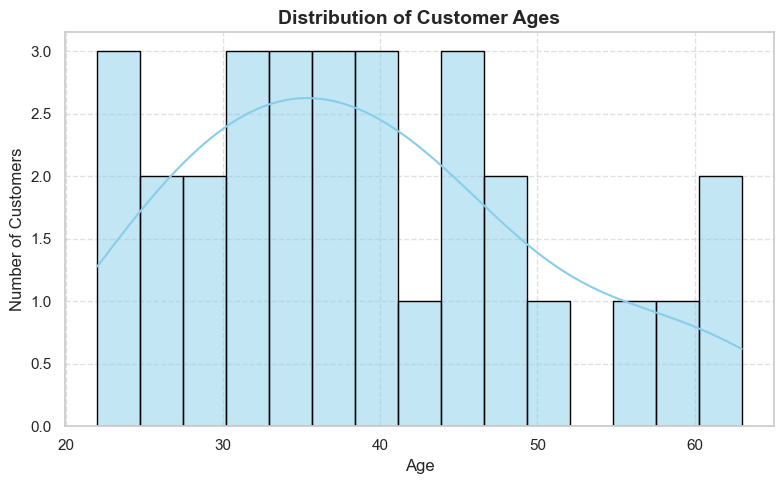

In [78]:

# =============================================================
# 1) Customer Age Distribution (1D Visualization - Histogram)
# =============================================================
plt.figure(figsize=(8, 5))
sns.histplot(customers['Age'], bins=15, kde=True, color='skyblue', edgecolor='black')

plt.title('Distribution of Customer Ages', fontsize=14, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


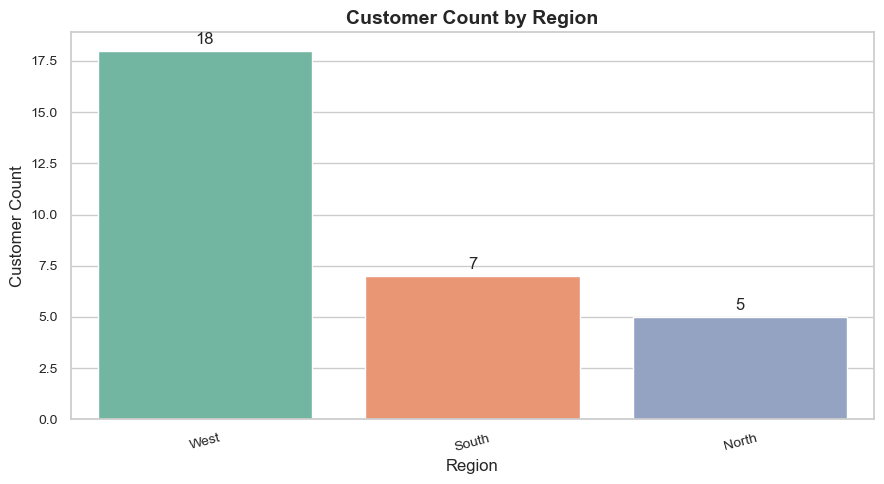

In [79]:

# =============================================================
# 2) Number of Customers in Each Region (Bar Plot)
# =============================================================
plt.figure(figsize=(9, 5))
region_counts = customers['Region'].value_counts()

ax = sns.barplot(
    x=region_counts.index, 
    y=region_counts.values, 
    palette='Set2'
)

plt.title('Customer Count by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Customer Count', fontsize=12)
plt.xticks(rotation=15, fontsize=10)
plt.yticks(fontsize=10)

# Add data labels on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


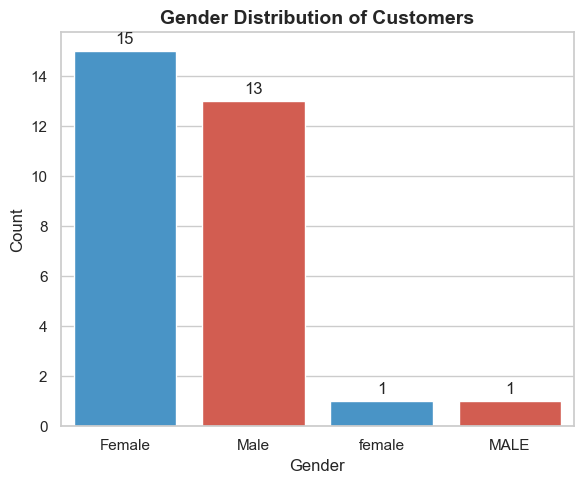

In [80]:

# =============================================================
# 3) Gender-wise Distribution of Customers (Bar Plot)
# =============================================================
plt.figure(figsize=(6, 5))
gender_counts = customers['Gender'].value_counts()

ax2 = sns.barplot(
    x=gender_counts.index, 
    y=gender_counts.values, 
    palette=['#3498db', '#e74c3c']
)

plt.title('Gender Distribution of Customers', fontsize=14, fontweight='bold')
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Add data labels on top of bars
for container in ax2.containers:
    ax2.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()


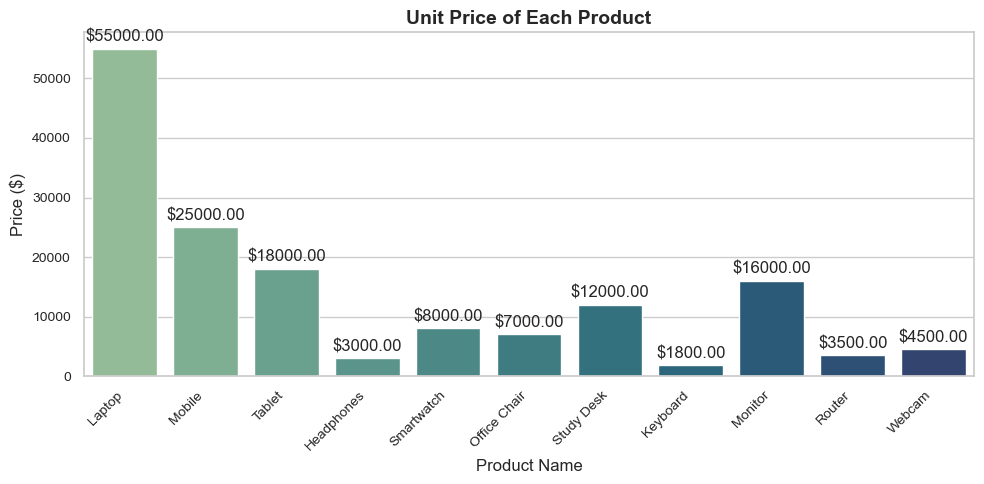

In [81]:

# =============================================================
# 4) Unit Price of Each Product (Bar Plot)
# =============================================================
plt.figure(figsize=(10, 5))

# Identify correct price column name automatically (Price vs Unit_Price)
price_col = 'Price' if 'Price' in products.columns else 'Unit_Price'

# Create bar plot
ax3 = sns.barplot(
    data=products, 
    x='Product_Name', 
    y=price_col, 
    palette='crest'
)

# Customization
plt.title('Unit Price of Each Product', fontsize=14, fontweight='bold')
plt.xlabel('Product Name', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)

# Rotate X-axis labels to prevent overlap
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Add price values on top of each bar
for container in ax3.containers:
    ax3.bar_label(container, fmt='$%.2f', padding=3)

plt.tight_layout()
plt.show()

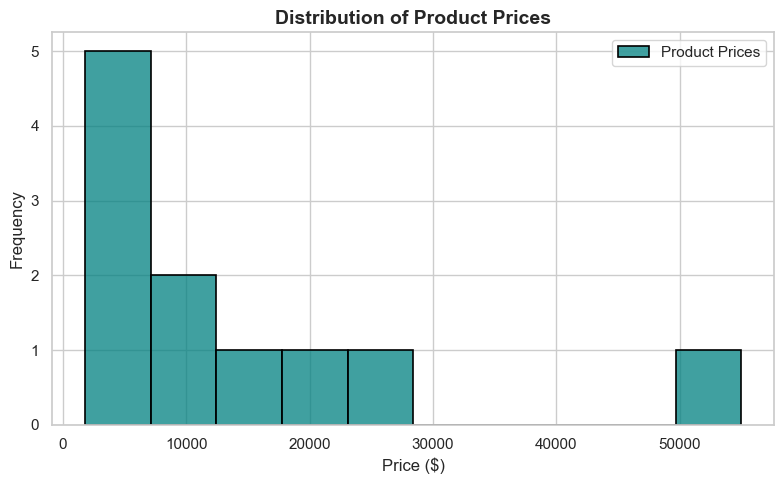

In [82]:
# =============================================================
# 5) Product Price Distribution (Histogram)
# =============================================================
plt.figure(figsize=(8, 5))
sns.histplot(
    products['Unit_Price'], 
    bins=10, 
    color='teal', 
    edgecolor='black', 
    linewidth=1.2, 
    label='Product Prices'
)

plt.title('Distribution of Product Prices', fontsize=14, fontweight='bold')
plt.xlabel('Price ($)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

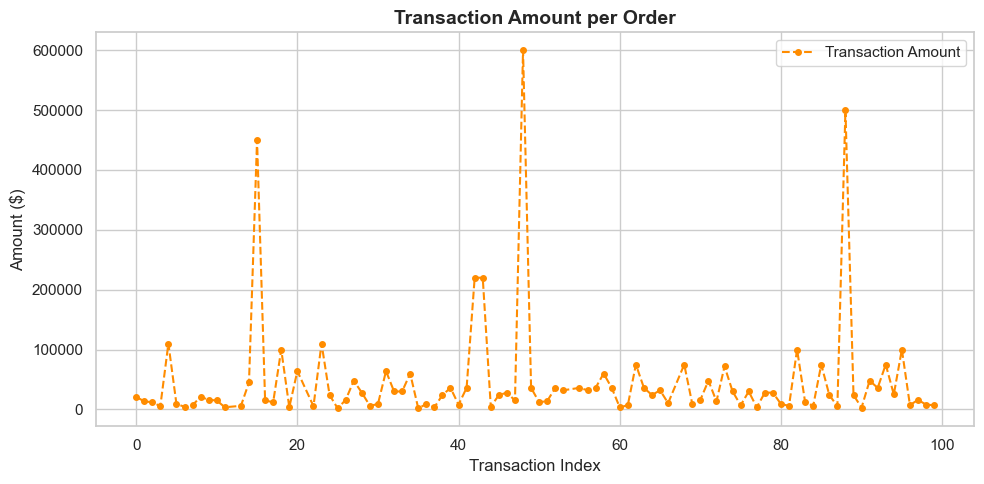

In [83]:
# =============================================================
# 6) Sales Amount per Transaction (Line Plot)
# =============================================================
plt.figure(figsize=(10, 5))
plt.plot(
    sales.index, 
    sales['Amount'], 
    linestyle='--', 
    marker='o', 
    color='darkorange', 
    markersize=4, 
    label='Transaction Amount'
)

plt.title('Transaction Amount per Order', fontsize=14, fontweight='bold')
plt.xlabel('Transaction Index', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

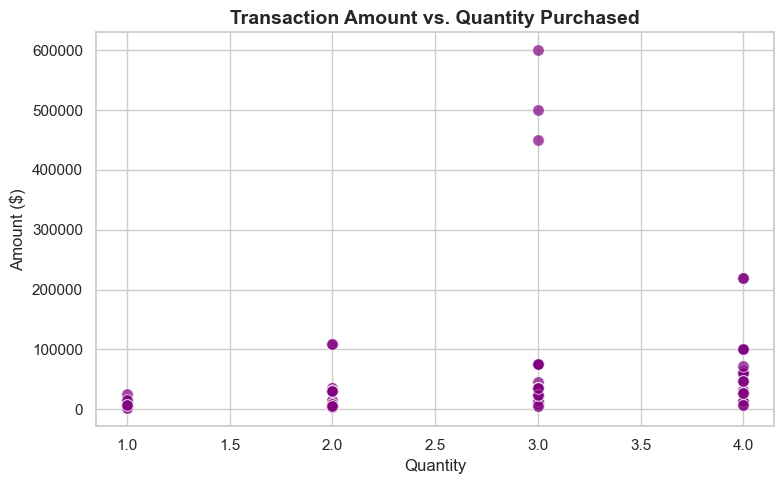

In [84]:
# =============================================================
# 7) Quantity vs. Amount (Scatter Plot)
# =============================================================
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sales, 
    x='Quantity', 
    y='Amount', 
    color='purple', 
    s=70, 
    alpha=0.7
)

plt.title('Transaction Amount vs. Quantity Purchased', fontsize=14, fontweight='bold')
plt.xlabel('Quantity', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.tight_layout()
plt.show()

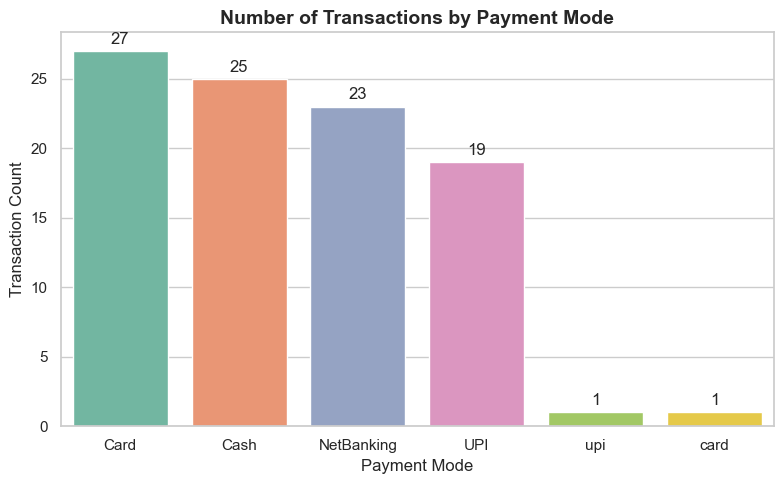

In [85]:
# =============================================================
# 8) Transactions by Payment Mode (Bar Plot)
# =============================================================
plt.figure(figsize=(8, 5))
payment_counts = sales['Payment_Mode'].value_counts()

ax = sns.barplot(
    x=payment_counts.index, 
    y=payment_counts.values, 
    palette='Set2'
)

plt.title('Number of Transactions by Payment Mode', fontsize=14, fontweight='bold')
plt.xlabel('Payment Mode', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

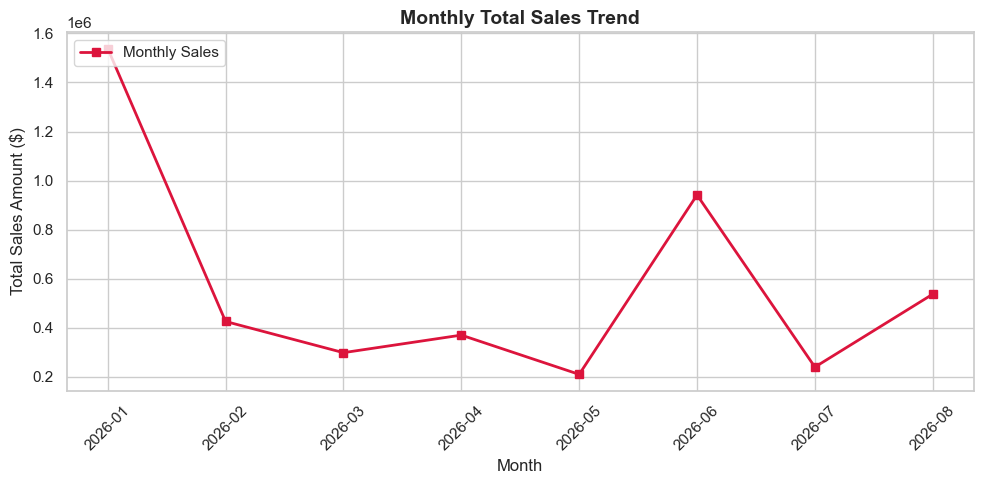

In [86]:
# =============================================================
# 9) Monthly Sales Trend (Line Plot)
# =============================================================
sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])
sales['YearMonth'] = sales['Order_Date'].dt.to_period('M')

monthly_sales = sales.groupby('YearMonth')['Amount'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales['YearMonth'], 
    monthly_sales['Amount'], 
    linestyle='-', 
    marker='s', 
    color='crimson', 
    linewidth=2, 
    label='Monthly Sales'
)

plt.title('Monthly Total Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales Amount ($)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

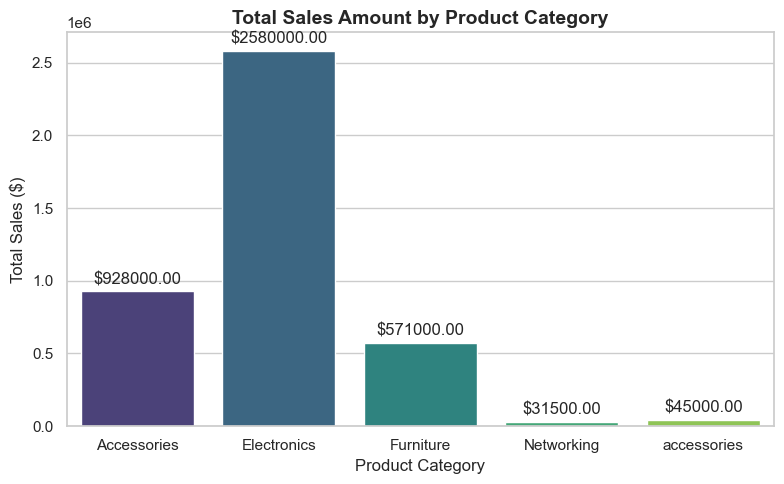

In [87]:
# =============================================================
# 10) Total Sales by Product Category (Merged Datasets)
# =============================================================
sales_products = pd.merge(sales, products, on='Product_ID')
cat_sales = sales_products.groupby('Category')['Amount'].sum().reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=cat_sales, x='Category', y='Amount', palette='viridis')

plt.title('Total Sales Amount by Product Category', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', padding=3)

plt.tight_layout()
plt.show()

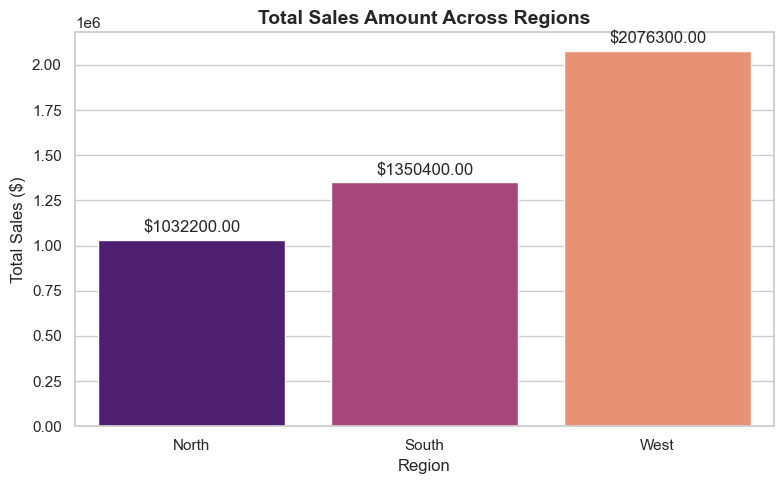

In [88]:
# =============================================================
# 11) Total Sales Across Regions (Merged Datasets)
# =============================================================
sales_customers = pd.merge(sales, customers, on='Customer_ID')
region_sales = sales_customers.groupby('Region')['Amount'].sum().reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=region_sales, x='Region', y='Amount', palette='magma')

plt.title('Total Sales Amount Across Regions', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='$%.2f', padding=3)

plt.tight_layout()
plt.show()

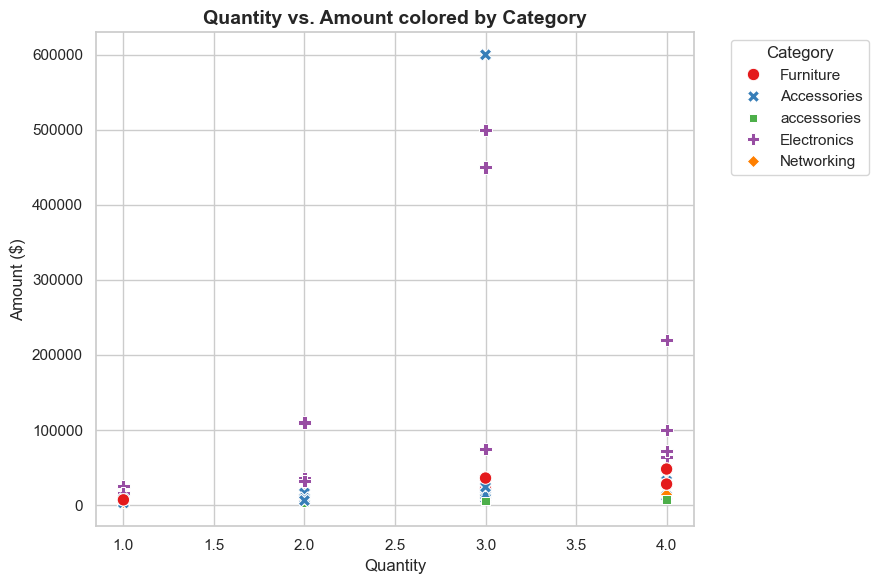

In [89]:
# =============================================================
# 12) Quantity vs. Amount by Product Category
# =============================================================
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sales_products, 
    x='Quantity', 
    y='Amount', 
    hue='Category', 
    style='Category', 
    s=80, 
    palette='Set1'
)

plt.title('Quantity vs. Amount colored by Category', fontsize=14, fontweight='bold')
plt.xlabel('Quantity', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

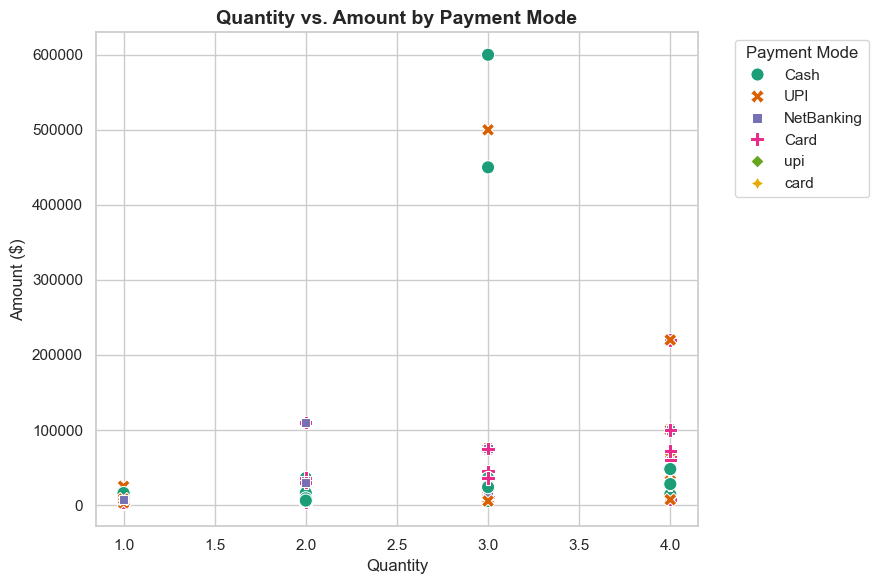

In [90]:
# =============================================================
# 13) Quantity vs. Amount by Payment Mode + Interpretation
# =============================================================
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=sales, 
    x='Quantity', 
    y='Amount', 
    hue='Payment_Mode', 
    style='Payment_Mode', 
    s=90, 
    palette='Dark2'
)

plt.title('Quantity vs. Amount by Payment Mode', fontsize=14, fontweight='bold')
plt.xlabel('Quantity', fontsize=12)
plt.ylabel('Amount ($)', fontsize=12)
plt.legend(title='Payment Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

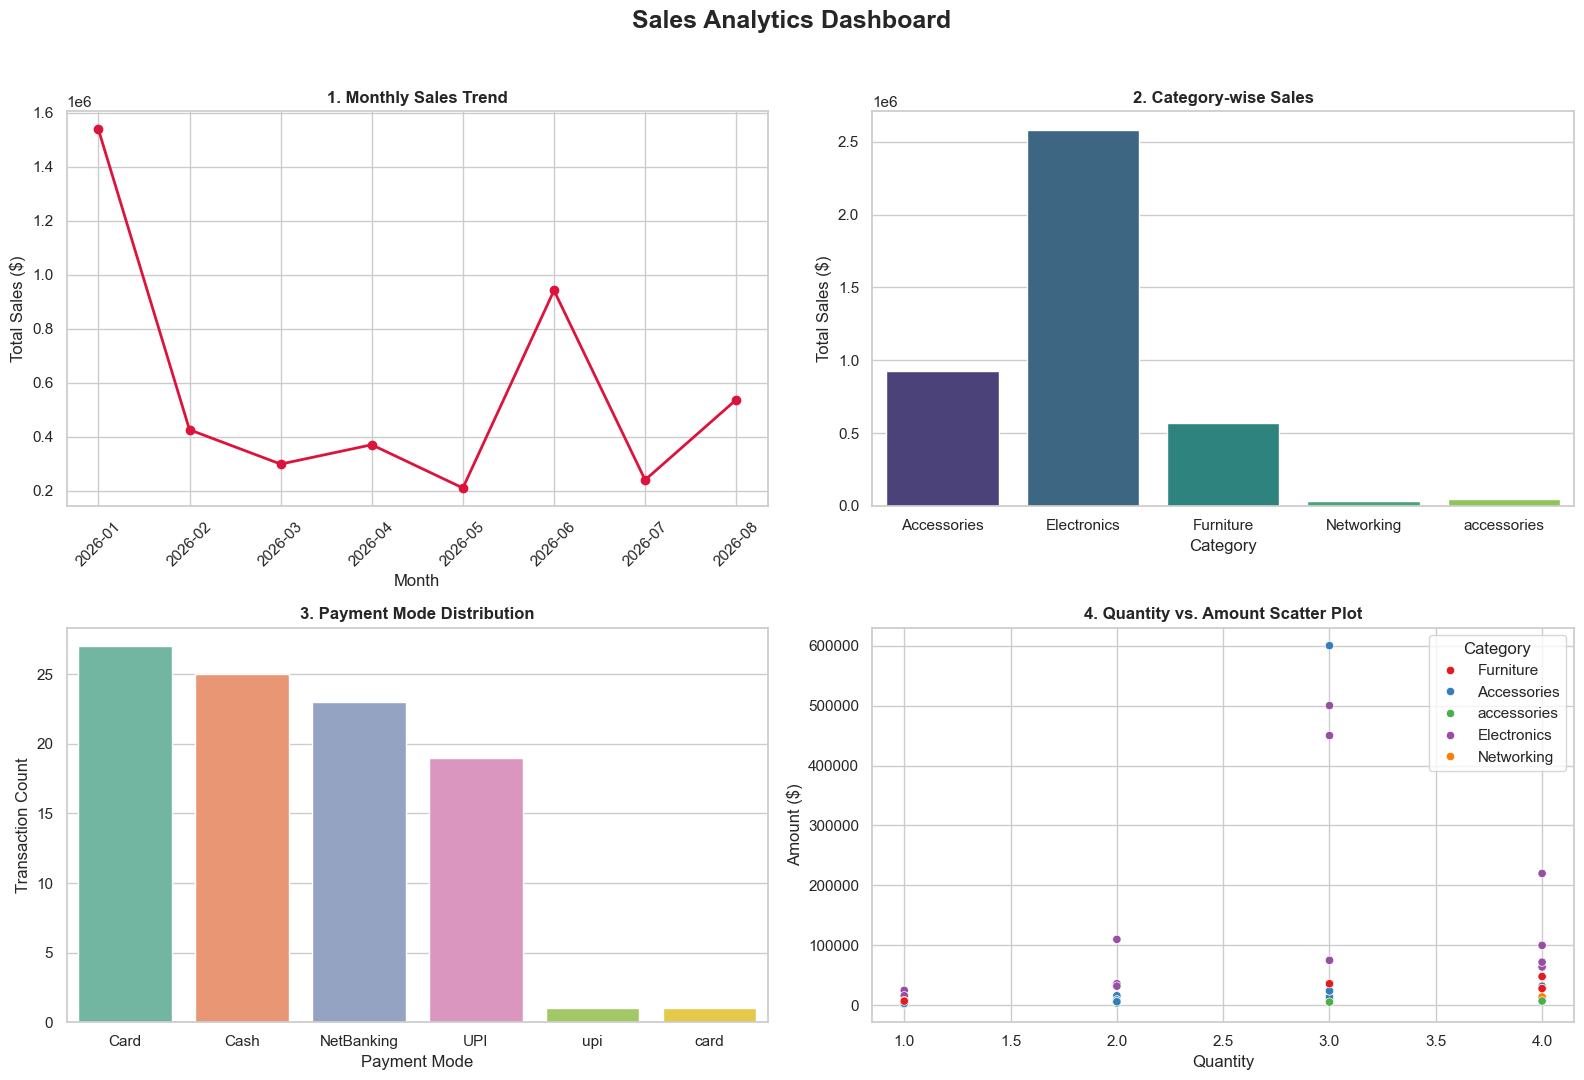

Dashboard successfully saved as 'Sales_Visualization_Dashboard.png'


In [91]:
# =============================================================
# 14) 2x2 Sales Visualization Dashboard (Saved to File)
# =============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('Sales Analytics Dashboard', fontsize=18, fontweight='bold', y=0.98)

# Subplot 1: Monthly Sales Trend
axes[0, 0].plot(
    monthly_sales['YearMonth'], 
    monthly_sales['Amount'], 
    marker='o', 
    color='crimson', 
    linewidth=2
)
axes[0, 0].set_title('1. Monthly Sales Trend', fontweight='bold')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('Total Sales ($)')
axes[0, 0].tick_params(axis='x', rotation=45)

# Subplot 2: Category-wise Sales
sns.barplot(
    data=cat_sales, 
    x='Category', 
    y='Amount', 
    ax=axes[0, 1], 
    palette='viridis'
)
axes[0, 1].set_title('2. Category-wise Sales', fontweight='bold')
axes[0, 1].set_xlabel('Category')
axes[0, 1].set_ylabel('Total Sales ($)')

# Subplot 3: Payment Mode Distribution
sns.barplot(
    x=payment_counts.index, 
    y=payment_counts.values, 
    ax=axes[1, 0], 
    palette='Set2'
)
axes[1, 0].set_title('3. Payment Mode Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Payment Mode')
axes[1, 0].set_ylabel('Transaction Count')

# Subplot 4: Quantity vs Amount Scatter Plot
sns.scatterplot(
    data=sales_products, 
    x='Quantity', 
    y='Amount', 
    hue='Category', 
    ax=axes[1, 1], 
    palette='Set1'
)
axes[1, 1].set_title('4. Quantity vs. Amount Scatter Plot', fontweight='bold')
axes[1, 1].set_xlabel('Quantity')
axes[1, 1].set_ylabel('Amount ($)')

# Save dashboard as image file
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('Sales_Visualization_Dashboard.png', dpi=300)
plt.show()
print("Dashboard successfully saved as 'Sales_Visualization_Dashboard.png'")